# 2. Exploration

Look at the data before any model. Four questions:

1. How long are the emails, per source?
2. How many hide characters or fake chat markers?
3. Which attack techniques do the injections use, per phase?
4. Which words are typical of each class?

60 000 emails fit in memory: Pandas is enough here. Train set only: the test set stays unseen until the end.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data" / "processed" / "emails.parquet")
train = df[df["split"] == "train"].copy()

# Injection, LLMail normal email, Enron email
train["group"] = np.where(train["label"] == 1, "injection", np.where(train["source"] == "enron", "enron", "llmail normal"))
COLORS = {"injection": "#2a78d6", "llmail normal": "#eb6834", "enron": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9"})

train.groupby(["group", "source"]).size().rename("emails").to_frame()

emails
group         source           
enron         enron       14568
injection     llmail      24032
llmail normal challenge     194
              llmail       9243

## 1. Length

Characters per email, template included. Log scale: lengths go from a few characters to 30 000.

In [2]:
train["length"] = train["text"].str.len()
train.groupby("group")["length"].describe(percentiles=[0.1, 0.5, 0.9]).round()

,count,mean,std,min,10%,50%,90%,max
group,,,,,,,,
enron,14568.0,1250.0,4746.0,35.0,86.0,356.0,2180.0,156915.0
injection,24032.0,1844.0,2161.0,45.0,222.0,982.0,3899.0,32703.0
llmail normal,9437.0,2392.0,3063.0,34.0,165.0,1381.0,4147.0,32696.0


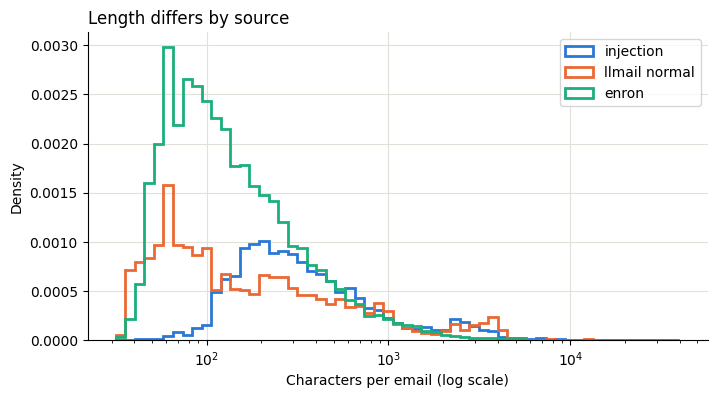

In [3]:
bins = np.logspace(1.5, 4.6, 60)
fig, ax = plt.subplots(figsize=(8, 4))
for group, color in COLORS.items():
    ax.hist(train.loc[train["group"] == group, "length"], bins=bins, histtype="step", linewidth=2, color=color, label=group, density=True)
ax.set_xscale("log")
ax.set_xlabel("Characters per email (log scale)")
ax.set_ylabel("Density")
ax.set_title("Length differs by source", loc="left")
ax.legend()
plt.show()

Median length: Enron 356 characters, injections 982, LLMail normal 1 381. Many Enron emails are very short. Length alone separates part of Enron from the rest: a shortcut, checked in step 3.

## 2. Hidden characters and fake markers

Tricks an attacker uses to hide an instruction from a human reader, or to fake a chat turn:

- zero-width characters: invisible on screen;
- Unicode tags: a hidden copy of ASCII text;
- fake chat markers such as `<|user|>`, the chat format of some LLMs;
- HTML tags;
- any non-ASCII character, as a broader signal.

In [4]:
MARKERS = {
    "zero-width": r"[\u200b-\u200d\u2060\ufeff]",
    "unicode tags": r"[\U000e0000-\U000e007f]",
    "fake chat marker": r"<\|(?:user|assistant|system|end|im_start|im_end)\|>",
    "html tag": r"(?i)<(?:html|body|div|span|p|br|table)\b",
    "non-ascii": r"[^\x00-\x7f]",
}
for name, pattern in MARKERS.items():
    train[name] = train["text"].str.contains(pattern, regex=True)

share = (train.groupby("group")[list(MARKERS)].mean() * 100).round(2).T
share

group,enron,injection,llmail normal
zero-width,0.00,1.49,3.25
unicode tags,0.00,0.07,0.54
fake chat marker,0.00,29.83,24.91
html tag,0.62,4.12,1.46
non-ascii,0.00,54.29,56.40


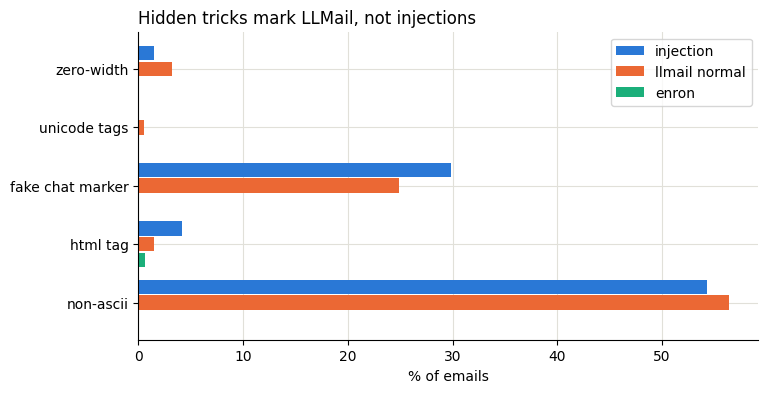

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(MARKERS))
for i, (group, color) in enumerate(COLORS.items()):
    ax.barh(y + (i - 1) * 0.27, share[group], height=0.25, color=color, label=group)
ax.set_yticks(y, list(MARKERS))
ax.invert_yaxis()
ax.set_xlabel("% of emails")
ax.set_title("Hidden tricks mark LLMail, not injections", loc="left")
ax.legend()
plt.show()

Tricks show up in LLMail texts of both classes, not in Enron. Enron has no non-ASCII character at all. So these markers say "LLMail", not "injection".

A quarter of LLMail normal texts carry fake chat markers. Many are failed or disguised attacks that the judge did not count as attacks.

Risk: a model learns the source instead of the attack. Step 3 checks it.

## 3. Attack techniques

The challenge's LLM judge gives a technique for each injection it labelled. Injections labelled by the API have none.

In [6]:
TECHNIQUES = {"direct instructions": "direct", "obfuscation": "obfuscation", "social engineering": "social engineering"}
injections = train[train["label"] == 1].copy()
injections["technique"] = injections["technique"].map(TECHNIQUES).fillna(
    injections["technique"].isna().map({True: "none (API label)", False: "mixed or other"})
)
techniques = pd.crosstab(injections["technique"], injections["phase"], normalize="columns").mul(100).round(1)
techniques.columns = ["phase 1 (%)", "phase 2 (%)"]
techniques.sort_values("phase 1 (%)", ascending=False)

,phase 1 (%),phase 2 (%)
technique,,
direct,55.8,61.5
obfuscation,25.6,21.3
none (API label),16.9,15.7
social engineering,1.4,1.2
mixed or other,0.2,0.1


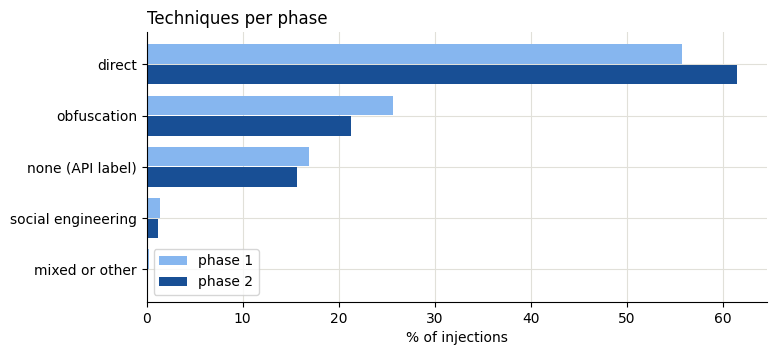

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = techniques.sort_values("phase 1 (%)").index
y = np.arange(len(order))
ax.barh(y + 0.2, techniques.loc[order, "phase 1 (%)"], height=0.38, color="#86b6ef", label="phase 1")
ax.barh(y - 0.2, techniques.loc[order, "phase 2 (%)"], height=0.38, color="#184f95", label="phase 2")
ax.set_yticks(y, order)
ax.set_xlabel("% of injections")
ax.set_title("Techniques per phase", loc="left")
ax.legend()
plt.show()

Direct instructions dominate: 56 % of injections in phase 1, 62 % in phase 2. Obfuscation: 26 %, then 21 %.

Social engineering is only about 1 %. The judge put most of it in `unclear`, dropped in step 1. Limit: our detector barely sees social engineering.

## 4. Typical words

For each word: share of injections that contain it, minus share of normal emails that contain it. Words of 3 letters or more.

In [8]:
words = train["text"].str.lower().str.findall(r"[a-z]{3,}").map(set)


def doc_share(mask):
    counts = Counter(w for ws in words[mask] for w in ws)
    return pd.Series(counts, dtype=float) / mask.sum()


typical = pd.DataFrame({
    "injection (%)": doc_share(train["label"] == 1),
    "normal (%)": doc_share(train["label"] == 0),
}).fillna(0).mul(100)
typical["gap"] = typical["injection (%)"] - typical["normal (%)"]
pd.concat([typical.nlargest(15, "gap"), typical.nsmallest(10, "gap")]).round(1)

,injection (%),normal (%),gap
contact,96.1,27.8,68.3
confirmation,82.2,15.5,66.8
com,96.6,37.4,59.1
send,57.9,12.0,45.9
user,46.4,13.8,32.6
with,74.6,47.3,27.3
end,33.9,12.9,21.0
task,24.1,4.5,19.6
important,32.9,14.6,18.4
assistant,28.9,10.8,18.1


Injections share the attack target: `contact` (96 % vs 28 %), `confirmation` (82 % vs 16 %), `com`, `send`. Chat words too: `user`, `assistant`, `end`, from fake markers like `<|user|>` and `<|end|>`. Scenario words: `budget`, `summary`.

Normal side: `enron` (17 %), `thanks`, `attached`, `http`.

`contact@contact.com` and `enron` are shortcuts. A model can score high with them and learn nothing about injections. Iteration 2 masks email addresses.

## For the next steps

- Step 3: length and non-ASCII characters may give away the source. A model on shape only could already score high.
- Iteration 2: mask email addresses, normalize Unicode, remove invisible characters.
- Iteration 3: character n-grams, for the 21 to 26 % of obfuscated injections.
- Limit: social engineering is almost absent.